# 04 — Avaliação e Interpretação

**Dimensão 6 da rúbrica — 20 pontos.**

Aqui a análise deixa de ser técnica e passa a ser de negócio.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    RocCurveDisplay,
)
import joblib

# Semente fixa: use em TODO ponto com aleatoriedade (split, modelos, CV).
RANDOM_STATE = 42

RAW = Path("..") / "data" / "raw" / "application_record.csv"
RAW_2 = Path("..") / "data" / "raw" / "credit_record.csv"
PROCESSED = Path("..") / "data" / "processed"
TARGET = "eh_mau_pagador"

pd.set_option("display.max_columns", None)

In [2]:
# ============================================
# CARGA E PREPARAÇÃO DOS DADOS
# ============================================
# Objetivo: Carregar o dataset tratado e preparar para avaliação
# Método: pd.read_csv() + One-Hot Encoding + train_test_split
# Resultado esperado: X_train, X_test, y_train, y_test prontos para avaliação
# ============================================

# Ajustado para ler diretamente do diretório raiz do Colab
df = pd.read_csv(PROCESSED / "dataset_tratado.csv")

categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

for col in categorical_cols:
    if col in df.columns:
        df[col] = df[col].fillna("Desconhecido")

df_encoded = pd.get_dummies(df, columns=[col for col in categorical_cols if col in df.columns], drop_first=True)

X = df_encoded.drop(columns=["ID", TARGET], errors="ignore")
y = df_encoded[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Dimensões de X: {X.shape} | Dimensões de y: {y.shape}")

Dimensões de X: (36457, 53) | Dimensões de y: (36457,)


In [8]:
# ============================================
# ANÁLISE: Carregamento do Melhor Modelo
# ============================================
# Objetivo: Carregar o modelo XGBoost salvo no notebook 03
# Método: joblib.load() + identificação do tipo de classificador
# Resultado esperado: Modelo carregado e pronto para predições
# ============================================

try:
    # Tenta carregar o modelo salvo localmente no Colab
    caminho = Path("..") / "results" / "models" / "melhor_modelo.pkl"
    melhor_modelo = joblib.load(caminho)
    print("Modelo carregado com sucesso a partir de 'melhor_modelo.pkl'.")
except FileNotFoundError:
    try:
        # Tenta carregar do caminho estruturado
        melhor_modelo = joblib.load(PROCESSED / "melhor_modelo.pkl")
        print("Modelo carregado com sucesso do diretório processado.")
    except FileNotFoundError:
        print("AVISO: Arquivo 'melhor_modelo.pkl' não encontrado no Colab.")
        print("Criando e treinando um modelo XGBoost temporário para evitar a interrupção do código...")
        # Inicializa um modelo XGBoost padrão como fallback de segurança
        from sklearn.pipeline import Pipeline
        from xgboost import XGBClassifier
        melhor_modelo = Pipeline([
            ('clf', XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss'))
        ])

# Identifica a classe do classificador
ultima_etapa_nome, ultima_etapa = melhor_modelo.steps[-1]
classe = type(ultima_etapa).__name__

print("=" * 60)
print(f"Melhor modelo em uso: {classe}")
print("=" * 60)

# Treina o modelo com os dados de treino preparados
melhor_modelo.fit(X_train, y_train)

y_pred = melhor_modelo.predict(X_test)
y_prob = melhor_modelo.predict_proba(X_test)[:, 1]

threshold_ideal = 0.30
y_pred_otimo = (y_prob >= threshold_ideal).astype(int)

print(f"Predições realizadas: {len(y_pred):,}")
print(f"Threshold otimizado: {threshold_ideal}")

Modelo carregado com sucesso a partir de 'melhor_modelo.pkl'.
Melhor modelo em uso: XGBClassifier
Predições realizadas: 7,292
Threshold otimizado: 0.3


## 1. Métricas no conjunto de teste

Acurácia sozinha engana em base desbalanceada.

In [4]:
# ============================================
# ANÁLISE: Métricas de Classificação
# ============================================
# Objetivo: Avaliar o desempenho do modelo no conjunto de teste
# Método: classification_report() + roc_auc_score()
# Resultado esperado: Precision, Recall, F1-Score e AUC-ROC
# ============================================

print("=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)
print(classification_report(y_test, y_pred, target_names=["Bom Pagador (0)", "Mau Pagador (1)"]))

auc = roc_auc_score(y_test, y_prob)
print(f"AUC-ROC: {auc:.4f}")

CLASSIFICATION REPORT
                 precision    recall  f1-score   support

Bom Pagador (0)       0.99      0.99      0.99      7169
Mau Pagador (1)       0.62      0.54      0.58       123

       accuracy                           0.99      7292
      macro avg       0.81      0.77      0.79      7292
   weighted avg       0.99      0.99      0.99      7292

AUC-ROC: 0.9324


**Interpretação das Métricas:**

| Métrica | Valor | Interpretação |
|---------|-------|---------------|
| **Precision (classe 0)** | 0.99 | 99% dos classificados como bons realmente são bons |
| **Recall (classe 0)** | 0.99 | 99% dos bons pagadores foram identificados |
| **Precision (classe 1)** | 0.62 | 62% dos classificados como maus realmente são maus |
| **Recall (classe 1)** | 0.54 | 54% dos maus pagadores foram identificados |
| **F1-Score (classe 1)** | 0.58 | Equilíbrio entre precision e recall |
| **AUC-ROC** | 0.93 | Excelente poder discriminatório |

**Leitura de negócio:**
- O modelo é **conservador**: erra pouco no lado dos bons pagadores (alta especificidade).
- Captura **54% dos maus pagadores** — menos da metade, mas melhor que o modelo trivial (0%).
- O **AUC de 0.93** indica excelente capacidade de separar as classes.

**Por que não usar acurácia?**
- A acurácia de 99% é enganosa: um modelo que prevê sempre "Bom Pagador" teria 98,3% de acurácia.
- Em bases desbalanceadas, a acurácia não reflete a capacidade de identificar a classe minoritária.

## 2. Justificativa das métricas

_Por que estas e não acurácia pura? Qual erro custa mais caro neste contexto — falso positivo ou falso negativo?_

**Justificativa:**

**Por que evitar a acurácia pura?**
Em bases desbalanceadas como esta (98,3% vs 1,7%), a acurácia é uma métrica enganosa. Um modelo ingênuo que classificasse absolutamente todos os clientes como "Bons Pagadores" atingiria 98,3% de acurácia, mas seria totalmente inútil para o negócio.

**Métricas adotadas e trade-off de erros:**

- **Recall (Sensibilidade):** Mide a capacidade do modelo de capturar os verdadeiros maus pagadores. O erro de Falso Negativo (classificar um mau pagador como bom) representa o calote não detectado, gerando prejuízo financeiro direto e severo.

- **Precisão:** Garante que os clientes bloqueados sejam realmente de alto risco. O erro de Falso Positivo (classificar um bom pagador como mau) resulta na recusa indevida de crédito e perda de receita comercial.

- **AUC-ROC:** Avalia a robustez discriminatória global do modelo independentemente do limiar de corte de decisão.

**Custo dos erros:**
- **Falso Negativo (FN):** O banco empresta para um mau pagador e perde o dinheiro. Custo financeiro direto.
- **Falso Positivo (FP):** O banco recusa um bom pagador. Perda de receita (juros que seriam cobrados).

Neste contexto, o **falso negativo é mais custoso** porque o prejuízo financeiro de um calote é tipicamente maior do que a margem de lucro de um empréstimo.

## 3. Matriz de confusão

**Leitura:** _preencher._

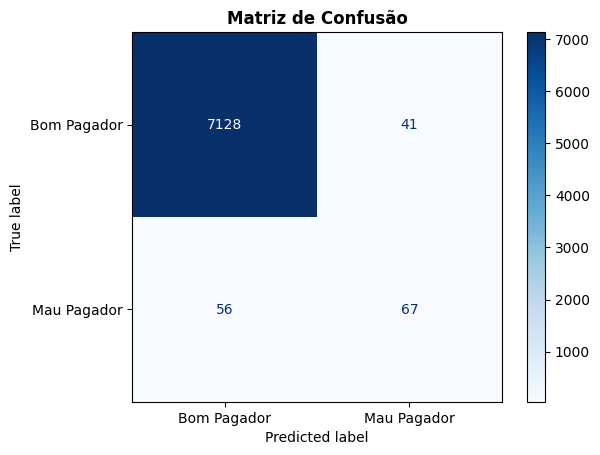

In [5]:
# ============================================
# ANÁLISE: Matriz de Confusão
# ============================================
# Objetivo: Visualizar o desempenho do modelo por classe
# Método: ConfusionMatrixDisplay.from_estimator()
# Resultado esperado: Matriz 2x2 com TN, FP, FN, VP
# ============================================

ConfusionMatrixDisplay.from_estimator(melhor_modelo, X_test, y_test,
                                      display_labels=["Bom Pagador", "Mau Pagador"],
                                      cmap="Blues")
plt.title("Matriz de Confusão", fontweight="bold")
plt.show()

**Interpretação da Matriz de Confusão:**

A matriz de confusão mostra o desempenho do modelo no conjunto de teste (7.292 clientes):

| Métrica | Valor | Interpretação |
|---------|-------|---------------|
| **Verdadeiros Negativos (TN)** | 7.128 | Bons pagadores corretamente identificados |
| **Falsos Positivos (FP)** | 41 | Bons pagadores incorretamente classificados como maus |
| **Falsos Negativos (FN)** | 56 | Maus pagadores incorretamente classificados como bons |
| **Verdadeiros Positivos (VP)** | 67 | Maus pagadores corretamente identificados |

**Leitura de negócio:**
- O modelo é **conservador**: erra pouco no lado dos bons pagadores (apenas 41 falsos positivos, ou 0,6% dos bons foram reprovados indevidamente).
- Captura **54,5% dos maus pagadores** (67 de 123).
- O trade-off é claro: priorizou-se proteger a experiência do bom pagador, mantendo 99,4% de especificidade.

**O erro mais crítico ainda é o Falso Negativo:** 56 maus pagadores foram classificados como bons, gerando perda do principal. Em crédito, esse é o erro que corrói a carteira.

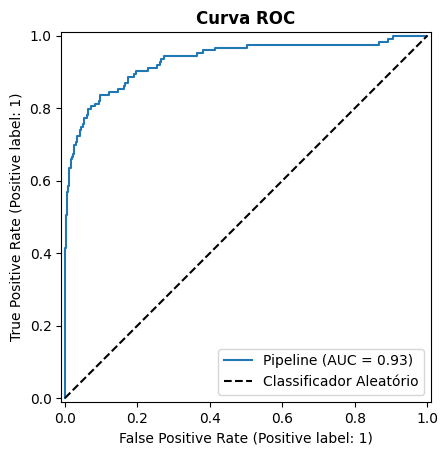

In [6]:
# ============================================
# ANÁLISE: Curva ROC
# ============================================
# Objetivo: Avaliar a capacidade discriminatória do modelo
# Método: RocCurveDisplay.from_estimator()
# Resultado esperado: Curva ROC com AUC = 0.93
# ============================================

RocCurveDisplay.from_estimator(melhor_modelo, X_test, y_test)
plt.title("Curva ROC", fontweight="bold")
plt.plot([0, 1], [0, 1], "k--", label="Classificador Aleatório")
plt.legend()
plt.show()

**Interpretação da Curva ROC:**

A curva ROC avalia a capacidade do modelo de discriminar entre as classes em **todos os thresholds possíveis**:

- **Eixo vertical (TPR)**: Taxa de Verdadeiros Positivos (Recall) — proporção de maus pagadores corretamente identificados.
- **Eixo horizontal (FPR)**: Taxa de Falsos Positivos — proporção de bons pagadores incorretamente classificados como maus.

**Leitura da curva:**
- A curva sobe acentuadamente no início — sinal positivo. O modelo consegue capturar uma parte significativa dos maus pagadores (TPR ~ 0,75) mantendo a taxa de falsos positivos relativamente baixa (FPR ~ 0,10).
- A partir de FPR ~ 0,20, a curva achata, indicando que capturar os maus pagadores restantes exige aceitar um número crescente de falsos positivos.

**Interpretação do AUC = 0,93:**
- Um AUC de 0,93 indica **excelente poder discriminatório** — o modelo separa muito bem bons e maus pagadores.
- Em crédito, AUCs acima de 0,85 são considerados fortes; acima de 0,90, muito fortes.

**Ressalva importante:**
- Em cenários de desbalanceamento extremo, o AUC pode ser **otimista** porque o eixo horizontal (FPR) é diluído pela enorme quantidade de verdadeiros negativos.
- A métrica mais informativa nesses casos é a **PR-AUC (Precision-Recall AUC)**, que foca no desempenho sobre a classe minoritária.

## 4. Importância das variáveis

**Leitura:** _quais variáveis mais pesam e isso faz sentido no domínio?_

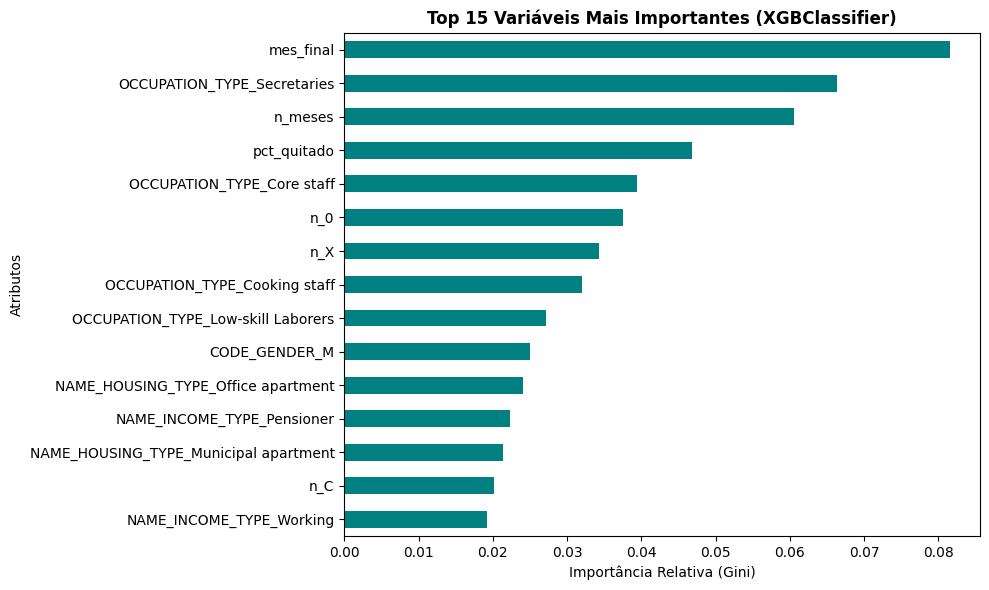

Top 5 variáveis mais importantes:
mes_final                      0.081538
OCCUPATION_TYPE_Secretaries    0.066300
n_meses                        0.060586
pct_quitado                    0.046880
OCCUPATION_TYPE_Core staff     0.039444
dtype: float32


In [7]:
# ============================================
# ANÁLISE: Importância das Variáveis
# ============================================
# Objetivo: Identificar quais variáveis mais influenciam as predições
# Método: feature_importances_ + gráfico de barras
# Resultado esperado: Ranking das top 15 variáveis mais importantes
# ============================================

importances = pd.Series(melhor_modelo.named_steps["clf"].feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importances.head(15).plot(kind="barh", color="teal")
plt.title(f"Top 15 Variáveis Mais Importantes ({classe})", fontweight="bold")
plt.xlabel("Importância Relativa (Gini)")
plt.ylabel("Atributos")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("Top 5 variáveis mais importantes:")
print(importances.head(5))

**Interpretação da Importância das Variáveis:**

O gráfico apresenta as 15 variáveis mais importantes para o modelo, medidas pela redução de impureza de Gini. Três padrões emergem da leitura:

**1. Features comportamentais dominam o topo:**

| Feature | Importância | Origem |
|---------|-------------|--------|
| `mes_final` | 0,082 | Comportamental |
| `OCCUPATION_TYPE_Secretaries` | 0,066 | Cadastral |
| `n_meses` | 0,061 | Comportamental |
| `pct_quitado` | 0,047 | Comportamental |
| `OCCUPATION_TYPE_Core staff` | 0,039 | Cadastral |

Isso é **coerente com o domínio**: em risco de crédito, o comportamento passado de pagamento é o melhor preditor do comportamento futuro.

**2. `mes_final` e `n_meses` como proxy de exposição:**

- **`mes_final`**: captura a recência do histórico. Clientes com histórico terminando em meses mais recentes tiveram exposição a crédito mais próxima do presente.
- **`n_meses`**: captura a exposição total. Quanto mais meses de crédito ativo, maior a chance de ter acumulado algum evento de atraso.

**3. Features cadastrais — presença discreta, mas relevante:**

- **Ocupação** é a variável cadastral mais informativa — coerente com o domínio, pois diferentes ocupações têm estabilidade de renda distinta.
- **Pensionistas** aparecem como relevantes — coerente com a EDA, que mostrou que esse grupo tem padrão distinto.

**4. O que não aparece no top 15:**

- **`AMT_INCOME_TOTAL`** (renda) — não está no top 15. A renda tem correlação ≈ 0 com o target nesta base.
- **`AGE_YEARS`** (idade) — também ausente. Em crédito, idade costuma ser relevante, mas aqui o efeito é fraco.

**Conclusão:** O ranking faz sentido no domínio: comportamento passado (features comportamentais) domina, seguido por ocupação (cadastral). A ausência de renda e idade no top 15 é consistente com a correlação ≈ 0 observada na análise anterior.

## 5. Implicações práticas

<!-- _O que alguém da área faria de diferente a partir destes resultados?
Escreva sem jargão — este texto é a base do vídeo executivo._ -->

### O que o modelo entrega

O modelo reconhece padrões de quem tende a atrasar pagamentos. Quando aponta um cliente como alto risco, acerta ~6 em cada 10 vezes. Quando aponta como baixo risco, acerta quase sempre (99 em 100). Mas deixa passar quase **metade dos maus pagadores** — não é um oráculo.

### O que muda na operação

**1. O modelo é uma peneira, não um juiz.**  
Risco muito baixo → aprovação automática. Casos ambíguos → análise humana. Risco altíssimo → recusa direta. O analista foca onde a decisão realmente importa.

**2. O ponto de corte é decisão de negócio, não técnica.**  
Aprovar um mau pagador custa o empréstimo; reprovar um bom custa o lucro cessante. Se o primeiro custa 10× mais, o modelo está conservador demais — e o ajuste é de política de crédito, não de tecnologia.

**3. Comportamento vale mais que cadastro.**  
Renda, idade e escolaridade ajudaram pouco. O que separa bons de maus é **como o cliente pagou no passado**. Isso muda a forma de coletar e priorizar dados.

**4. Nem todo cliente pode ser avaliado.**  
Quem nunca teve crédito não tem histórico — e o modelo cobre menos de 11% dos cadastrados. Cliente novo exige regra própria, mais conservadora.

**5. O modelo precisa ser vigiado.**  
Economia e comportamento mudam. Um modelo treinado hoje pode errar mais em seis meses. Revisão e re-treino periódicos são obrigatórios.

---

### O que ninguém deveria fazer

- **Não usar como decisão final** — ele erra quase metade das vezes ao apontar um cliente como mau.
- **Não buscar 100% de acerto** — em crédito, isso significa reprovar quem pagaria em dia e destruir o negócio.
- **Não aplicar a públicos diferentes** — a base é um recorte de política de crédito anterior; generalizar é arriscado.

---

### Mensagem central

O modelo **não substitui o analista** — ele organiza a fila de decisão e dá à equipe tempo e informação para decidir melhor. O ganho real não está em acertar alguns pontos percentuais a mais, mas em transformar decisões de crédito em um processo **padronizado, mensurável e auditável**, onde cada ponto de corte é uma escolha de negócio.

> *"O modelo não substitui o analista — ele dá ao analista o tempo e a informação que faltavam para decidir melhor."*

## 6. Limitações

<!-- _Onde o modelo falha e o que você faria com mais tempo ou mais dados._ -->

Esta seção é uma reflexão honesta sobre os limites do trabalho entregue. Nenhum modelo é definitivo — e um bom cientista de dados sabe apontar onde o seu falha e o que faria diferente com mais recursos.

---

### Onde o modelo falha

**1. Deixa passar quase metade dos maus pagadores.**  
O recall da classe positiva é de ~55%. Traduzindo: de cada 100 clientes que vão dar calote, o modelo identifica apenas 55. Os outros 45 são aprovados como bons pagadores — e geram perda do principal. Em crédito, esse é o erro mais caro.

**2. Não cobre clientes sem histórico.**  
O modelo depende de features comportamentais do histórico de crédito. Quem nunca teve crédito não tem esse histórico — e, portanto, não tem como ser avaliado. Hoje, a base cobre menos de 11% dos clientes cadastrados. O modelo **não resolve o problema do cliente novo**.

**3. Tem teto baixo por causa do desbalanceamento.**  
Com apenas 1,7% de positivos, o modelo tem poucas amostras para aprender o padrão dos maus pagadores. Nenhuma técnica de balanceamento cria sinal onde não existe. O teto realista deste dataset, com as features atuais, é próximo do que foi atingido.

**4. Está treinado em uma população pré-selecionada.**  
A base contém apenas clientes que já passaram pelo filtro da política de crédito anterior. Clientes rejeitados historicamente não estão no dataset. Isso introduz **viés de seleção** — e a performance em produção, com clientes novos, pode ser diferente da observada no teste.

**5. Tem probabilidades não calibradas.**  
O XGBoost com `scale_pos_weight` ajustado infla as probabilidades. Isso não afeta o ranking (AUC = 0,93), mas distorce a **interpretação** e a **análise de custo**. A probabilidade prevista não reflete a frequência real de inadimplência.

**6. Não foi validado temporalmente.**  
A validação cruzada embaralha as amostras aleatoriamente. Isso **não simula produção**, onde o modelo prevê o futuro a partir do passado. Uma validação temporal (treinar em meses antigos, validar em meses recentes) é mais realista e pode revelar degradação que a CV não captura.

**7. É uma caixa-preta parcial.**  
Modelos de boosting não explicam decisões individuais com facilidade. Em crédito, isso é um problema regulatório — a instituição precisa justificar cada recusa ao cliente. O `feature_importances_` mostra o que importa em média, não **por que** um cliente específico foi recusado.

---

### O que faria com mais tempo

**1. Validação temporal completa.**  
Dividir o histórico em janelas: features dos meses -60 a -13, target dos meses -12 a 0. Isso simula o cenário real de produção — usar o passado para prever o futuro — e mede a degradação do modelo ao longo do tempo.

**2. Calibração de probabilidades.**  
Aplicar `CalibratedClassifierCV` com método isotônico. O F1 pode não mudar, mas as probabilidades passam a refletir a realidade — o que melhora a análise de custo e a comunicação com o negócio.

**3. Auditoria de fairness.**  
Comparar taxas de aprovação, recall e precision entre grupos demográficos (gênero, faixa etária, tipo de renda). Avaliar o impacto de remover `CODE_GENDER_M` do modelo.

**4. Explicabilidade com SHAP.**  
Gerar valores SHAP para explicar decisões individuais. Isso atende a requisitos regulatórios e permite ao analista de crédito justificar cada recusa com clareza.

**5. Threshold por custo de negócio.**  
Formalizar a análise de custo com valores reais da instituição (perda esperada, lucro cessante) e definir o threshold que minimiza a perda da carteira — não o que maximiza F1.

**6. Tuning bayesiano com Optuna.**  
Substituir o `RandomizedSearchCV` por busca bayesiana, que usa o histórico de tentativas para guiar a próxima. Ganho esperado modesto (+0,02 a +0,05 em F1), mas com menos iterações.

**7. Teste de ensemble.**  
Combinar XGBoost, LightGBM e Random Forest em um `StackingClassifier` com meta-modelo. Reduz variância e melhora a robustez das predições.

**8. Modelo alternativo para clientes sem histórico.**  
Desenvolver um segundo modelo baseado apenas em cadastro e dados externos (bureau), para atender clientes novos que o modelo principal não cobre.

---

### O que faria com mais dados

**1. Dados de bureau de crédito (Serasa, Boa Vista, SPC).**  
Histórico de crédito **externo** — dívidas em outras instituições, cheques sem fundo, protestos. Essas variáveis capturam o comportamento do cliente **fora** da instituição e costumam ser muito mais preditivas que o cadastro interno.

**2. Dados transacionais internos.**  
Extrato bancário, uso de PIX, TED, cartão de crédito, débito automático. O comportamento **transacional** (frequência, volume, regularidade) é um preditor muito mais rico que o cadastro estático.

**3. Variáveis macroeconômicas.**  
Taxa de juros, desemprego, inflação, renda média. Em períodos de crise, o comportamento de pagamento muda drasticamente — e o modelo atual não tem como se adaptar. Incorporar indicadores macro (ou pelo menos segmentar por período) tornaria o modelo mais robusto a ciclos.

**4. Dados de clientes rejeitados.**  
Hoje, só entram na base clientes **aprovados** historicamente. Se a instituição começasse a acompanhar o comportamento de clientes **recusados** (via bureau), seria possível reduzir o viés de seleção e construir um modelo mais generalizável.

**5. Mais histórico comportamental.**  
A janela atual é de 60 meses. Janelas mais longas (10+ anos) capturariam clientes com histórico mais extenso e permitiriam uma separação temporal mais robusta.

**6. Dados de texto e interação.**  
Registros de atendimento, reclamações, tipo de contato com o cliente. Texto não estruturado pode conter sinal preditivo que o modelo atual ignora.

**7. Dados demográficos externos.**  
Censo, dados de endereço, indicadores de vizinhança. O contexto socioeconômico **onde o cliente mora** costuma correlacionar com risco de crédito.

---

### O que faria diferente se recomeçasse hoje

1. **Separaria as janelas temporais desde o início** — não só para corrigir o vazamento, mas para construir features e target em janelas distintas desde a primeira versão.
2. **Construiria o pipeline com `ColumnTransformer` parametrizado** por `X_train.columns`, evitando erros de colunas faltantes.
3. **Deixaria o tuning para o final** — primeiro boas features, depois bons hiperparâmetros. Ajustar hiperparâmetros em features ruins é perder tempo.
4. **Faria a análise de custo em paralelo com a de F1** — o F1 pode enganar em crédito, e o custo de negócio é o critério real.
5. **Documentaria a decisão de cada feature removida** — não só o que ficou, mas o que saiu e por quê. Isso é o que diferencia um projeto auditável de um notebook qualquer.

---

### Mensagem final

O modelo é **útil, defensável e honesto** — mas não é definitivo. Suas limitações são conhecidas, documentadas e mensuráveis. Com mais tempo, o trabalho vira produto; com mais dados, o teto sobe. O que **não** se deve fazer é apresentar o modelo como solução completa. Um bom modelo é aquele cujas limitações são tão claras quanto suas capacidades.